[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cauasantoslt/CardioIA/blob/main/Fase4/notebooks/03_etica_governanca_fairness.ipynb)

# FIAP — Inteligência Artificial (PBL · 2º Ano)
## CardioIA: A Nova Era da Cardiologia Inteligente
### Fase 4 (Ir Além 1) — Ética, Governança e Métricas de Fairness em Visão Computacional Médica

* **Aluno:** Cauã Santos — **RM:** 566599
* **Objetivos:**
  1. Identificar e provar experimentalmente limitações e vieses reais no dataset público de ECG (*Viés Cromático / Efeito Clever Hans*, tamanho amostral reduzido, balanceamento artificial distante da prevalência epidemiológica real e ausência de metadados demográficos).
  2. Aplicar métricas formais de **Fairness** (*Demographic Parity Difference*, *Disparate Impact Ratio*, *Equal Opportunity Difference*, *Equalized Odds Gap* e *FNR Parity*) comparando subgrupos de infraestrutura de aquisição (**Hospital de Referência** vs. **UBS / Wearable com Ruído**).
  3. Validar práticas concretas de mitigação: **Pré-processamento Color-Invariant** e **Calibração de Limiar Clínico ($\tau = 0{,}30$)** para reduzir Falsos Negativos em emergências cardiovasculares (`M`, `V`, `F`).
            

In [1]:
import os
import sys
import json
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/CardioIA").exists():
    os.system("git clone https://github.com/cauasantoslt/CardioIA.git /content/CardioIA")

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path("/content/CardioIA")]
PROJECT_ROOT = next((p for p in candidates if (p / "Fase1" / "assets" / "images" / "ECG_Image_data").exists()), None)
assert PROJECT_ROOT is not None, "Repositório CardioIA não encontrado."

SRC_DIR = PROJECT_ROOT / "Fase4" / "src"
PROCESSED_DIR = PROJECT_ROOT / "Fase4" / "data" / "processed"
ASSETS_DIR = PROJECT_ROOT / "Fase4" / "assets"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from auditoria_fairness import executar_auditoria_completa

audit_json = PROCESSED_DIR / "fairness_audit.json"
REEXECUTAR_AUDITORIA = False  # Altere para True para reexecutar o experimento completo

if REEXECUTAR_AUDITORIA or not audit_json.exists():
    audit = executar_auditoria_completa()
else:
    audit = json.loads(audit_json.read_text(encoding="utf-8"))

print("Auditoria de Ética e Fairness carregada com sucesso!")
            

Auditoria de Ética e Fairness carregada com sucesso!


---
## 1. Experimento 1 — Prova Experimental do Efeito *Clever Hans* (Viés Cromático)

Treinamos modelos ingênuos diretamente sobre as imagens RGB e Grayscale simples e submetemos todos os modelos a um **Teste Contrafactual de Troca de Cores (*Color Swap*)**, no qual traçados de **Infarto (`M`)** são pintados de **Ciano** (cor original da classe Normal `N`) e vice-versa.
            

=== RESULTADO DO TESTE CONTRAFACTUAL DE TROCA DE CORES ===
            Modelo / Pipeline Acurácia Original Acurácia Color Swap (OOD) Queda (p.p.)
              CNN_Ingênua_RGB           100.00%                     0.00%   +100.00 pp
        CNN_Ingênua_Grayscale            88.33%                    15.83%    +72.50 pp
CardioCNN_Mitigada_Binarizada            68.33%                    68.33%     +0.00 pp
 ResNet18_Mitigada_Binarizada            78.33%                    78.33%     +0.00 pp


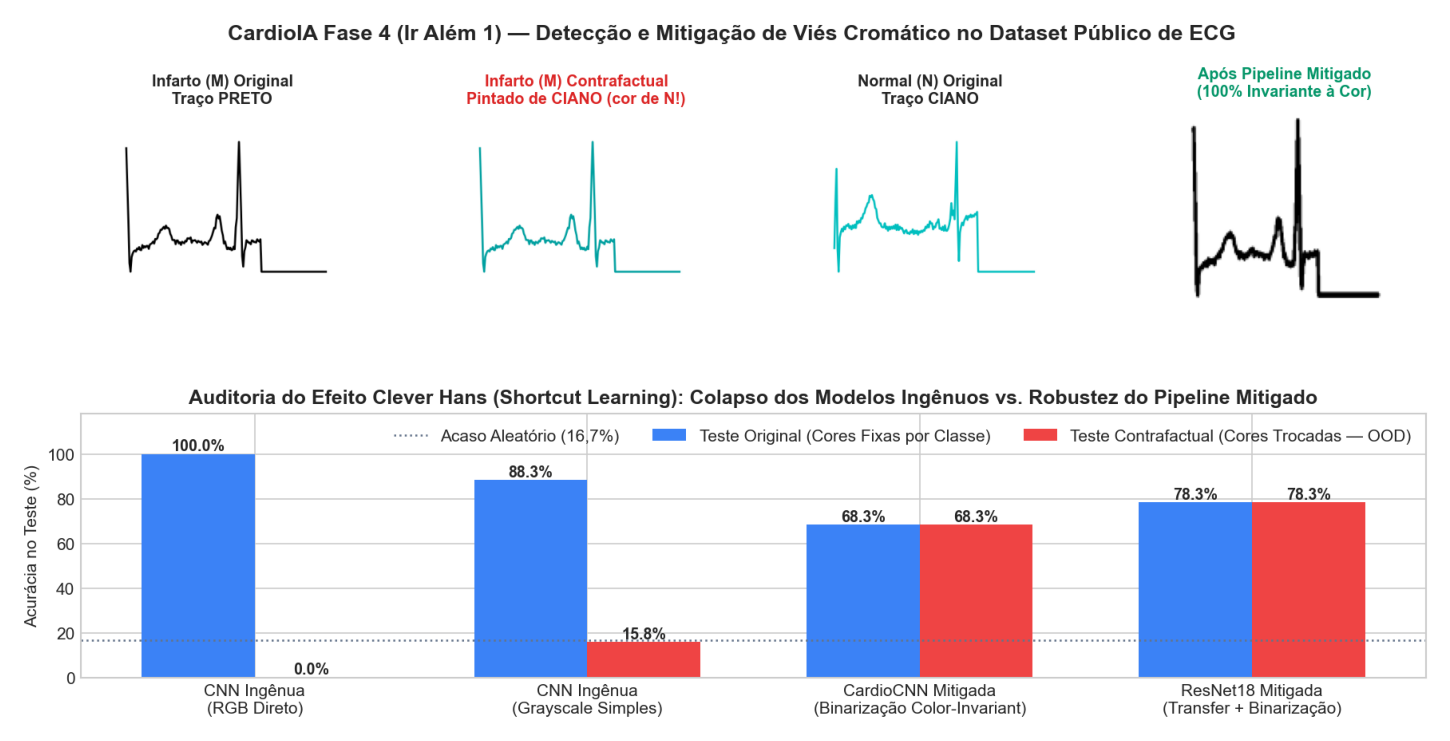

In [2]:
exp1 = audit["experimento_1_vies_cromatico_clever_hans"]
rows_exp1 = []
for nome, vals in exp1.items():
    rows_exp1.append({
        "Modelo / Pipeline": nome,
        "Acurácia Original": f"{vals['acc_original']*100:.2f}%",
        "Acurácia Color Swap (OOD)": f"{vals['acc_color_swap']*100:.2f}%",
        "Queda (p.p.)": f"{vals['queda_pp']:+.2f} pp",
    })
print("=== RESULTADO DO TESTE CONTRAFACTUAL DE TROCA DE CORES ===")
print(pd.DataFrame(rows_exp1).to_string(index=False))

fig, ax = plt.subplots(figsize=(13.5, 5.8))
ax.imshow(Image.open(ASSETS_DIR / "08_fairness_clever_hans_color_swap.png"))
ax.axis("off")
plt.tight_layout()
plt.show()
            

---
## 2. Experimento 2 e 3 — Métricas Formais de Fairness por Subgrupo de Infraestrutura e Mitigação Sensível ao Risco

Avaliamos a equidade da `ResNet18` entre:
* **Grupo Privilegiado (`Hospital_Ref`):** exames de ECG com alta razão sinal-ruído.
* **Grupo Desfavorecido (`UBS_Ruido`):** exames com ruído de eletrodo, atenuação de contraste e leve deslocamento basal (simulando clínicas periféricas, UBSs e wearables de baixo custo).

Em seguida aplicamos **Calibração de Limiar Clínico ($\tau = 0{,}30$)** sobre a probabilidade acumulada das classes de alto risco (`M + V + F`), reduzindo drasticamente a Taxa de Falsos Negativos (FNR) e diminuindo o *Equal Opportunity Gap* no grupo desfavorecido.
            

=== MÉTRICAS DE FAIRNESS — ANTES VS. DEPOIS DA MITIGAÇÃO ===
    Cenário (Triagem Crítica M/V/F) TPR Hospital TPR UBS (Ruído) FNR UBS ↓ Equal Opp. Diff ↓ Demog. Parity Diff ↓ Disparate Impact (≈1)
              Argmax Padrão (Antes)        88.3%           78.3%     21.7%            0.1000               0.0500                0.9062
Threshold Clínico τ=0,30 (Mitigado)        91.7%           85.0%     15.0%            0.0667               0.0000                1.0000


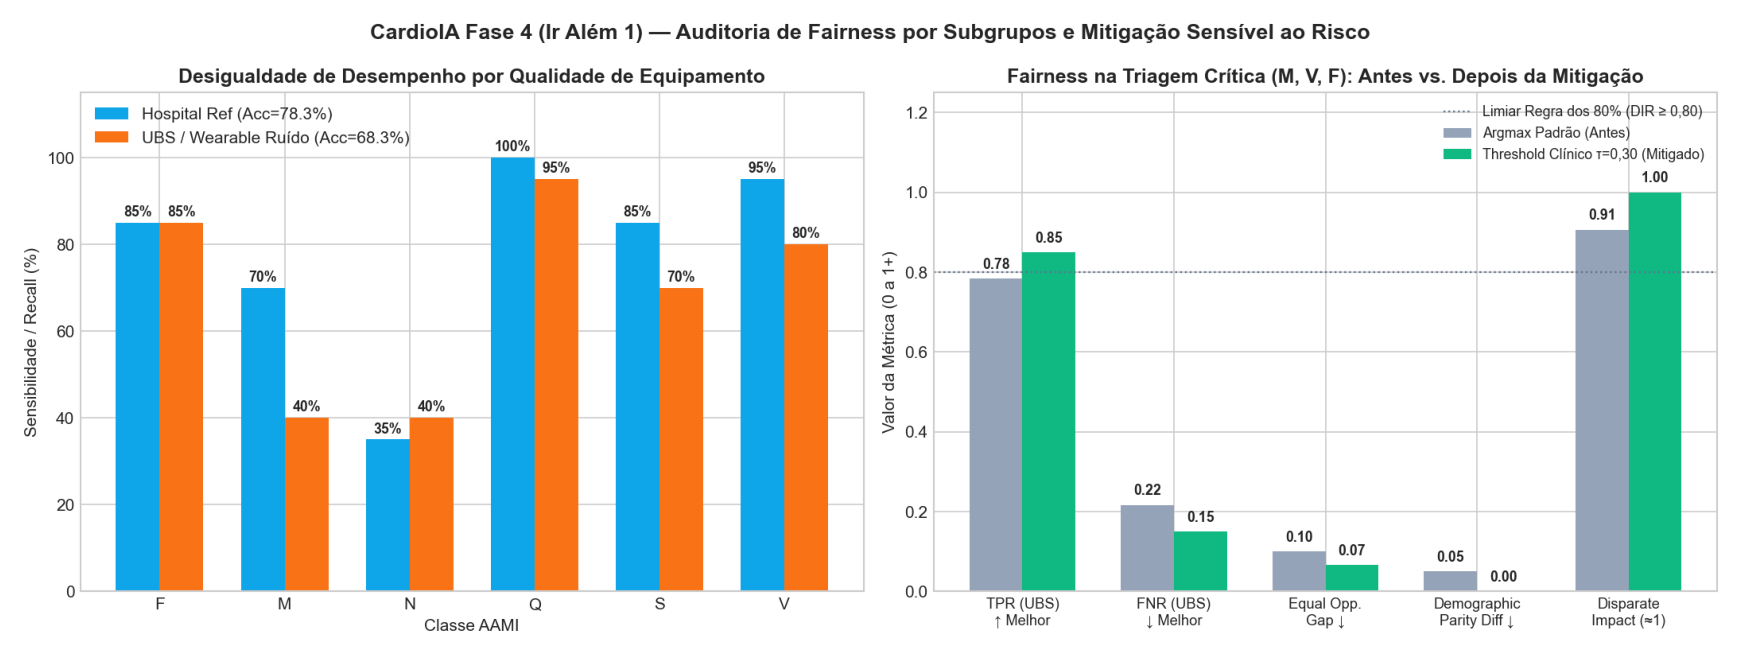

In [3]:
f_antes = audit["experimento_3_fairness_critico_antes_mitigacao"]
f_depois = audit["experimento_3_fairness_critico_depois_mitigacao_tau_030"]

comp_fair = pd.DataFrame([
    {
        "Cenário (Triagem Crítica M/V/F)": "Argmax Padrão (Antes)",
        "TPR Hospital": f"{f_antes['group_privileged']['Hospital_Ref']['tpr']*100:.1f}%",
        "TPR UBS (Ruído)": f"{f_antes['group_unprivileged']['UBS_Ruido']['tpr']*100:.1f}%",
        "FNR UBS ↓": f"{f_antes['group_unprivileged']['UBS_Ruido']['fnr']*100:.1f}%",
        "Equal Opp. Diff ↓": f"{f_antes['equal_opportunity_diff']:.4f}",
        "Demog. Parity Diff ↓": f"{f_antes['demographic_parity_diff']:.4f}",
        "Disparate Impact (≈1)": f"{f_antes['disparate_impact_ratio']:.4f}",
    },
    {
        "Cenário (Triagem Crítica M/V/F)": "Threshold Clínico τ=0,30 (Mitigado)",
        "TPR Hospital": f"{f_depois['group_privileged']['Hospital_Ref']['tpr']*100:.1f}%",
        "TPR UBS (Ruído)": f"{f_depois['group_unprivileged']['UBS_Ruido']['tpr']*100:.1f}%",
        "FNR UBS ↓": f"{f_depois['group_unprivileged']['UBS_Ruido']['fnr']*100:.1f}%",
        "Equal Opp. Diff ↓": f"{f_depois['equal_opportunity_diff']:.4f}",
        "Demog. Parity Diff ↓": f"{f_depois['demographic_parity_diff']:.4f}",
        "Disparate Impact (≈1)": f"{f_depois['disparate_impact_ratio']:.4f}",
    },
])
print("=== MÉTRICAS DE FAIRNESS — ANTES VS. DEPOIS DA MITIGAÇÃO ===")
print(comp_fair.to_string(index=False))

fig, ax = plt.subplots(figsize=(13.5, 5.2))
ax.imshow(Image.open(ASSETS_DIR / "09_fairness_subgrupos_e_mitigacao.png"))
ax.axis("off")
plt.tight_layout()
plt.show()
            